# Three optical receivers, one fiber link: coherent vs. Kramers-Kronig vs. dispersion-assisted phase retrieval

This is the next step from the ECE 279AS project's "further work" list: **compare the phase-retrieval receiver with the methods used today** [1], [2], [4], [6]. One simulated 32 GBd fiber link, three ways to get the phase back, the same noise for all three, and an honest scorecard.

## The idea, for programmers (in the spirit of Feynman)

A photodiode is a function that returns `abs(E)**2`. It throws away the phase, the part of the complex number that carries the data. Every receiver below is a trick for getting that phase back.

- **Coherent receiver: compare against a reference.** Keep a second laser at the receiver (the local oscillator, LO), and add it to the signal before squaring. `abs(LO + E)**2 - abs(LO - E)**2 = 4*Re(conj(LO)*E)`. The cross term *is* the field. Do it again with the LO rotated 90° and you get `Im` too. It's like reading a clock by holding it next to a reference clock. It works very well, but costs a second laser, an optical "hybrid" and four photodiodes.
- **Kramers-Kronig (KK) receiver: add a big constant so `log` is safe.** Send a strong carrier tone `C` along with the signal `s`. If `C > abs(s)`, then `C + s` never reaches zero. That means `log(C + s)` is smooth, and its real part (the log of the amplitude, which you *can* measure) determines its imaginary part (the phase) through a Hilbert transform [4]. One photodiode, but most of the power goes into the carrier.
- **Dispersion-assisted phase retrieval: take several blurry photos and solve the puzzle.** Split the light into five copies, smear each one in time by a different known amount of dispersion, and photograph each `abs(...)**2`. Only one phase makes all five photos come out right. Gerchberg-Saxton finds it by going back and forth between them [1], [2]. No second laser and no carrier, but five photodiodes and an iterative solver.

All three receivers finish the same way: undo the fiber's dispersion digitally, use two pilot symbols to fix the constant phase offset, and decide the bits.

**Everything here is simulated.** The receiver models are idealized (no laser phase noise, ideal optical hybrid, single wavelength channel). The numbers show the trade-offs; they are not a hardware measurement.

In [1]:
import sys, pathlib, time
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from dgs import receivers as R
sp.init_printing()
OKABE = {'coherent': '#000000', 'KK': '#0072B2', 'GS': '#D55E00'}
STYLE = {'coherent': '-', 'KK': '--', 'GS': ':'}
MARK = {'coherent': 'o', 'KK': 's', 'GS': '^'}
L = 20e3; B2L = R.BETA2*L; A_LOSS = np.sqrt(10**(-R.ALPHA_DB_KM*L/1000/10))
TAPS = np.array([-2500, -5000, -10000, -20000, -40000.0])/(2*np.pi*R.FS**2)   # the five dispersive branches
ps_nm = lambda b2L: -2*np.pi*R.C0*b2L/(1550e-9)**2*1e3                  # s^2 -> ps/nm
print(f'symbol rate {R.RS/1e9:.0f} GBd, {R.SPS} samples/symbol, frames of {R.N_SYM} symbols (2 pilots + 6 data)')
print(f'fiber: {L/1e3:.0f} km standard single-mode, beta2 = {R.BETA2*1e27:.1f} ps^2/km, loss {R.ALPHA_DB_KM} dB/km, gamma = {R.GAMMA*1e3:.1f} /(W km)')
print('GS receiver branches (dispersion):', ', '.join(f'{ps_nm(d):.0f}' for d in TAPS), 'ps/nm')

symbol rate 32 GBd, 32 samples/symbol, frames of 8 symbols (2 pilots + 6 data)
fiber: 20 km standard single-mode, beta2 = -21.7 ps^2/km, loss 0.2 dB/km, gamma = 1.3 /(W km)
GS receiver branches (dispersion): 298, 595, 1190, 2380, 4760 ps/nm


## 1. The fiber: the split-step Fourier method

Light in fiber obeys the nonlinear Schrödinger equation [5]:
$$\frac{\partial A}{\partial z} = -\frac{\alpha}{2}A \;-\; \frac{i\beta_2}{2}\frac{\partial^2 A}{\partial t^2} \;+\; i\gamma |A|^2 A$$
(loss, dispersion, and the Kerr effect, where the light's own power shifts its phase). Each term is easy alone: dispersion is a multiplication in the frequency domain, and the Kerr effect is a multiplication in the time domain. The split-step method alternates the two in small steps. SymPy checks the two facts it relies on: the dispersion step has unit magnitude (it moves energy around but never adds or removes it), and the Kerr step only changes the phase.

In [2]:
w, b2, dz, g, A = sp.symbols('omega beta_2 dz gamma A', real=True)
D_step = sp.exp(sp.I*b2*dz*w**2/2)
K_step = sp.exp(sp.I*g*A**2*dz)
print('|dispersion step| =', sp.simplify(sp.Abs(D_step)), '   |Kerr step| =', sp.simplify(sp.Abs(K_step)))
E0 = R.transmit([0, 1, 2, 3, 3, 2], 1e-3)
for nl in (False, True):
    E1 = R.fiber(E0, L, nonlinear=nl)
    print(f'nonlinear={nl}: output/input power = {np.mean(abs(E1)**2)/np.mean(abs(E0)**2):.4f}  (expected {A_LOSS**2:.4f} from {R.ALPHA_DB_KM*L/1e3:.0f} dB of loss)')

|dispersion step| = 1    |Kerr step| = 1
nonlinear=False: output/input power = 0.3981  (expected 0.3981 from 4 dB of loss)
nonlinear=True: output/input power = 0.3981  (expected 0.3981 from 4 dB of loss)


## 2. All three receivers on a clean link

No noise at all: each receiver should decode every frame. If one didn't, the comparison below would be measuring a bug.

In [3]:
rng = np.random.default_rng(0); ok = dict(coherent=0, KK=0, GS=0); n_frames = 20
for _ in range(n_frames):
    data = list(rng.integers(0, 4, 6)); want = R.PILOT + data
    E_rx = R.fiber(R.transmit(data, 1e-3), L, nonlinear=False)
    ok['coherent'] += list(R.rx_coherent(E_rx, B2L, R.RS)) == want
    E_kk, ca, sa = R.kk_tx(data, 1e-3, 10, R.RS)
    ok['KK'] += list(R.rx_kk(R.fiber(E_kk, L, nonlinear=False), B2L, ca*A_LOSS, sa*A_LOSS, R.RS, R.RS)) == want
    ok['GS'] += list(R.rx_gs(R.gs_branches(E_rx, TAPS, 0.0, rng, R.RS), TAPS, B2L, rng)[0]) == want
print({k: f'{v}/{n_frames}' for k, v in ok.items()})

{'coherent': '20/20', 'KK': '20/20', 'GS': '20/20'}


## 3. The photodiode front end (SPICE)

Every photodiode feeds a transimpedance amplifier (TIA) that turns photocurrent into voltage and adds its own noise. The circuit is in `spice/tia_frontend.cir`, a PSpice/ngspice netlist you can run in the lab. Here SymPy solves the same circuit (node analysis at the amplifier input). The result sets the bandwidth and the thermal noise used for every photodiode in the link.

Node equation at the input: I_ph = V_in·sC_pd + (V_in − V_out)(1/R_f + sC_f), with V_out = −A(s)V_in and A(s) = A₀/(1 + s/ω_p).

transimpedance Z(s) = V_out / I_ph =


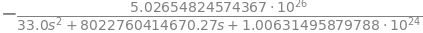

DC gain 500 ohm, -3 dB bandwidth 28.3 GHz, peaking 0.00 dB
input-referred noise: 20.1 pA/sqrt(Hz) averaged over 0-32 GHz (resistor alone: 5.76)
-> each photodiode adds 6.36 uW of noise (rms); the received power is 0.398 mW


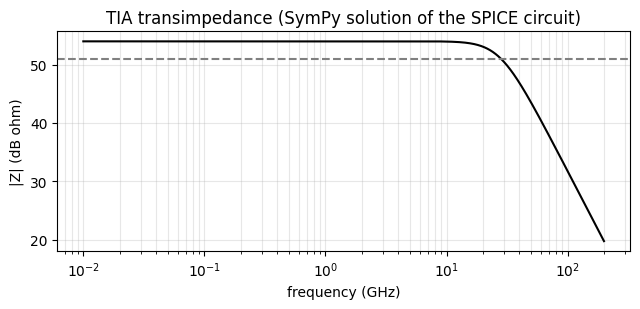

Figure: transimpedance magnitude in dB-ohm versus frequency (log axis), flat near 54 dB-ohm (500 ohm) and falling past the
-3 dB line (grey dashes) near 28 GHz.


In [4]:
s = sp.symbols('s'); Vin, Vout, Iph = sp.symbols('V_in V_out I_ph')
Rf, Cf, Cpd, A0, wp = 500, sp.Rational(15, 10**15), sp.Rational(150, 10**15), 1000, 2*sp.pi*400e6
Aamp = A0/(1 + s/wp)
sol = sp.solve([sp.Eq(Iph, Vin*s*Cpd + (Vin - Vout)*(1/Rf + s*Cf)), sp.Eq(Vout, -Aamp*Vin)], [Vin, Vout], dict=True)[0]
Zt = sp.simplify(sol[Vout]/Iph)
print('transimpedance Z(s) = V_out / I_ph ='); display(Zt)
Zf = sp.lambdify(s, Zt, 'numpy')
f = np.logspace(7, 11.3, 4000); Zm = np.abs(Zf(2j*np.pi*f))
f3 = f[np.argmax(Zm < Zm[0]/np.sqrt(2))]
kB, T, en = 1.380649e-23, 300, 1e-9                    # en: amplifier input voltage noise (illustrative), V/sqrt(Hz)
fb = np.linspace(1e6, R.RS, 4000)
i_n = np.sqrt(4*kB*T/Rf + (en*np.abs(1/Rf + 2j*np.pi*fb*float(Cpd + Cf)))**2)
I_N = float(np.sqrt(np.mean(i_n**2)))
print(f'DC gain {Zm[0]:.0f} ohm, -3 dB bandwidth {f3/1e9:.1f} GHz, peaking {20*np.log10(Zm.max()/Zm[0]):.2f} dB')
print(f'input-referred noise: {I_N*1e12:.1f} pA/sqrt(Hz) averaged over 0-{R.RS/1e9:.0f} GHz (resistor alone: {np.sqrt(4*kB*T/Rf)*1e12:.2f})')
RESP = 0.8                                                # photodiode responsivity, A/W
SIGMA_TH = I_N*np.sqrt(2*R.RS)/RESP                       # thermal noise per photodiode, in optical-power units (W)
print(f'-> each photodiode adds {SIGMA_TH*1e6:.2f} uW of noise (rms); the received power is {1e3*1e-3*A_LOSS**2:.3f} mW')
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.semilogx(f/1e9, 20*np.log10(Zm), color='#000000'); ax.axhline(20*np.log10(Zm[0]/np.sqrt(2)), color='0.5', ls='--')
ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('|Z| (dB ohm)'); ax.set_title('TIA transimpedance (SymPy solution of the SPICE circuit)'); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()
print('Figure: transimpedance magnitude in dB-ohm versus frequency (log axis), flat near 54 dB-ohm (500 ohm) and falling past the')
print('-3 dB line (grey dashes) near 28 GHz.')

## 4. Bit error rate versus optical noise

Same transmitter power (1 mW launch), same fiber, the same amplifier noise (OSNR, measured in the standard 0.1 nm bandwidth), and the TIA noise above at every photodiode. The penalties each receiver pays are built in:
- **coherent:** none beyond the noise; it measures the field directly.
- **KK:** the carrier gets 10× the signal power (CSPR 10 dB), so the data part is weak.
- **GS:** the light is split five ways (7 dB less per photodiode), and the phase comes out of an iterative solver that can occasionally lock onto a wrong answer.

The 150 frames per point (1,800 bits) can resolve BERs down to about 5 × 10⁻⁴; "0" means no errors in that sample.

In [5]:
def bits(sym): return ''.join(f'{R.INV[q]:02b}' for q in sym)

def ber_point(osnr_db, P_launch, frames, seed, nonlinear=False):
    rng = np.random.default_rng(seed); err = dict(coherent=0, KK=0, GS=0); nb = 0
    for _ in range(frames):
        data = list(rng.integers(0, 4, 6)); tb = bits(data); nb += len(tb)
        E_rx = R.ase(R.fiber(R.transmit(data, P_launch), L, nonlinear=nonlinear), osnr_db, rng)
        err['coherent'] += sum(a != b for a, b in zip(tb, bits(R.rx_coherent(E_rx, B2L, R.RS)[2:])))
        E_kk, ca, sa = R.kk_tx(data, P_launch, 10, R.RS)
        E_kk_rx = R.ase(R.fiber(E_kk, L, nonlinear=nonlinear), osnr_db, rng)
        err['KK'] += sum(a != b for a, b in zip(tb, bits(R.rx_kk(E_kk_rx, B2L, ca*A_LOSS, sa*A_LOSS, R.RS, R.RS, SIGMA_TH, rng)[2:])))
        d_gs = R.rx_gs(R.gs_branches(E_rx, TAPS, SIGMA_TH, rng, R.RS), TAPS, B2L, rng)[0]
        err['GS'] += sum(a != b for a, b in zip(tb, bits(d_gs[2:])))
    return {k: v/nb for k, v in err.items()}, nb

t0 = time.time()
OSNRS = [16, 20, 24, 28, 32, 36, 40]
curves = {k: [] for k in OKABE}
for o in OSNRS:
    b, nb = ber_point(o, 1e-3, 150, seed=o)
    for k in curves: curves[k].append(b[k])
    print(f'OSNR {o:2d} dB: ' + '   '.join(f'{k} {v:.1e}' for k, v in b.items()))
print(f'({nb} bits per point, {time.time() - t0:.0f} s)')

OSNR 16 dB: coherent 5.0e-03   KK 4.9e-01   GS 4.5e-01


OSNR 20 dB: coherent 0.0e+00   KK 4.1e-01   GS 4.3e-01


OSNR 24 dB: coherent 0.0e+00   KK 2.2e-01   GS 9.6e-02


OSNR 28 dB: coherent 0.0e+00   KK 3.6e-02   GS 2.1e-02


OSNR 32 dB: coherent 0.0e+00   KK 3.9e-03   GS 5.0e-03


OSNR 36 dB: coherent 0.0e+00   KK 0.0e+00   GS 0.0e+00


OSNR 40 dB: coherent 0.0e+00   KK 0.0e+00   GS 0.0e+00
(1800 bits per point, 605 s)


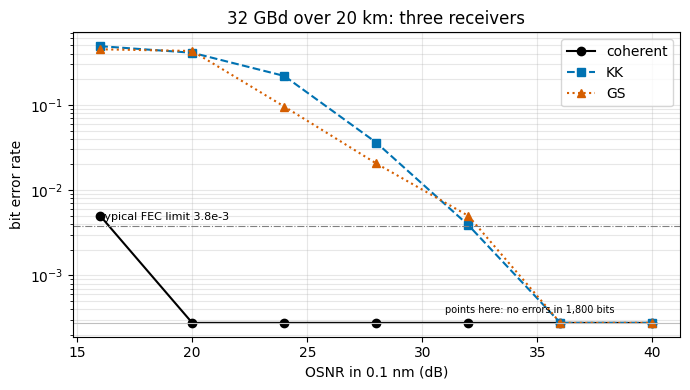

Figure: bit error rate (log axis) versus OSNR for the coherent receiver (black solid, circles), Kramers-Kronig (blue dashed,
squares) and dispersion-assisted GS (orange dotted, triangles). Points on the light grey line had no errors in the sample.


In [6]:
floor = 1/(150*12)
fig, ax = plt.subplots(figsize=(7, 4))
for k in OKABE:
    y = [max(v, floor/2) for v in curves[k]]
    ax.semilogy(OSNRS, y, color=OKABE[k], ls=STYLE[k], marker=MARK[k], label=k)
ax.axhline(3.8e-3, color='0.5', lw=0.8, ls='-.'); ax.text(OSNRS[0], 4.5e-3, 'typical FEC limit 3.8e-3', fontsize=8)
ax.axhline(floor/2, color='0.75', lw=0.8); ax.text(OSNRS[-1] - 9, floor/2*1.3, 'points here: no errors in 1,800 bits', fontsize=7)
ax.set_xlabel('OSNR in 0.1 nm (dB)'); ax.set_ylabel('bit error rate'); ax.set_title('32 GBd over 20 km: three receivers'); ax.legend(); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()
print('Figure: bit error rate (log axis) versus OSNR for the coherent receiver (black solid, circles), Kramers-Kronig (blue dashed,')
print('squares) and dispersion-assisted GS (orange dotted, triangles). Points on the light grey line had no errors in the sample.')

## 5. Turning up the power: the Kerr effect

More launch power beats the noise, but in fiber it also adds the Kerr phase shift (γ|A|²). None of these receivers undoes that, so it shows up as distortion. Here the OSNR is held at 36 dB and the launch power is raised.

In [7]:
for dbm in (0, 6, 10, 13):
    b, _ = ber_point(36, 1e-3*10**(dbm/10), 150, seed=200 + dbm, nonlinear=True)
    phi_nl = R.GAMMA*1e-3*10**(dbm/10)*(1 - A_LOSS**2)/(R.ALPHA_DB_KM/1000*np.log(10)/10)
    print(f'launch {dbm:2d} dBm (peak Kerr phase {phi_nl:.2f} rad): ' + '   '.join(f'{k} {v:.1e}' for k, v in b.items()))

launch  0 dBm (peak Kerr phase 0.02 rad): coherent 0.0e+00   KK 0.0e+00   GS 1.0e-02


launch  6 dBm (peak Kerr phase 0.07 rad): coherent 0.0e+00   KK 0.0e+00   GS 0.0e+00


launch 10 dBm (peak Kerr phase 0.17 rad): coherent 0.0e+00   KK 0.0e+00   GS 0.0e+00


launch 13 dBm (peak Kerr phase 0.34 rad): coherent 0.0e+00   KK 0.0e+00   GS 0.0e+00


## 6. What each receiver costs

Optical parts, detectors, and the digital work per 8-symbol frame (FFTs of 256 points). The GS count depends on how many restarts a frame needs, so it is measured here.

In [8]:
rng = np.random.default_rng(9); tries = []; t_c = t_k = t_g = 0.0
for _ in range(60):
    data = list(rng.integers(0, 4, 6)); E_rx = R.ase(R.fiber(R.transmit(data, 1e-3), L, nonlinear=False), 32, rng)
    t = time.perf_counter(); R.rx_coherent(E_rx, B2L, R.RS); t_c += time.perf_counter() - t
    E_kk, ca, sa = R.kk_tx(data, 1e-3, 10, R.RS); E_kr = R.ase(R.fiber(E_kk, L, nonlinear=False), 32, rng)
    t = time.perf_counter(); R.rx_kk(E_kr, B2L, ca*A_LOSS, sa*A_LOSS, R.RS, R.RS); t_k += time.perf_counter() - t
    Is = R.gs_branches(E_rx, TAPS, SIGMA_TH, rng, R.RS)
    t = time.perf_counter(); _, n, _ = R.rx_gs(Is, TAPS, B2L, rng); t_g += time.perf_counter() - t; tries.append(n)
fft_gs = np.mean(tries)*100*5*2 + 2
print(f"{'':12s} {'lasers at Rx':>12s} {'photodiodes':>11s} {'ADC channels':>12s} {'FFTs/frame':>11s} {'Python time/frame':>18s}")
print(f"{'coherent':12s} {'1 (LO)':>12s} {'4':>11s} {'4':>12s} {'4':>11s} {t_c/60*1e3:15.2f} ms")
print(f"{'KK':12s} {'0':>12s} {'1':>11s} {'1':>12s} {'6':>11s} {t_k/60*1e3:15.2f} ms")
print(f"{'GS':12s} {'0':>12s} {'5':>11s} {'5':>12s} {fft_gs:11.0f} {t_g/60*1e3:15.2f} ms")
print(f'GS restarts at 32 dB OSNR: mean {np.mean(tries):.2f}, max {max(tries)}  (each restart is 100 iterations x 5 planes x 2 FFTs)')

             lasers at Rx photodiodes ADC channels  FFTs/frame  Python time/frame
coherent           1 (LO)           4            4           4            0.07 ms
KK                      0           1            1           6            0.12 ms
GS                      0           5            5        1385           34.22 ms
GS restarts at 32 dB OSNR: mean 1.38, max 20  (each restart is 100 iterations x 5 planes x 2 FFTs)


## 7. The receiver math, proved in Lean

`lean/Receivers.lean` (Lean 4 + Mathlib):

| theorem | what it proves |
|---|---|
| `balanced_detection` | \|LO + E\|² − \|LO − E\|² = 4 Re(conj(LO)·E): a balanced photodiode pair measures the field |
| `quadrature_detection` | with the LO rotated 90°, the pair measures 4 Im(conj(LO)·E) |
| `kk_never_zero` | if the carrier is stronger than the signal, C + s is never zero, so the KK logarithm is defined |
| `kk_margin` | and it stays at least C − \|s\| away from zero |
| `split_conserves` | splitting into n branches loses no power, but each detector gets 1/n of it |
| `dispersion_undo` | the digital dispersion inverse exactly undoes the fiber's dispersion |

In [9]:
import shutil, subprocess, re
lean_file = ROOT / 'lean' / 'Receivers.lean'
names = re.findall(r'^theorem (\w+)', lean_file.read_text(encoding='utf-8'), re.M)
proj = pathlib.Path.home() / 'lean' / 'NavierStokesAndEuler'
if proj.exists() and shutil.which('lake'):
    r = subprocess.run(['lake', 'env', 'lean', str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1800)
    msg = r.stdout + r.stderr
    print(f'Lean + Mathlib: {len(names)} theorems accepted' if r.returncode == 0 and 'sorry' not in msg else
          ('NOT CHECKED: out of memory while loading Mathlib' if 'failed to read file' in msg else msg[-1500:]))
else:
    print(f'Lean + Mathlib not found here: {len(names)} theorems not checked on this machine')
print('  ' + ', '.join(names))

Lean + Mathlib: 6 theorems accepted
  balanced_detection, quadrature_detection, kk_never_zero, kk_margin, split_conserves, dispersion_undo


## Conclusions (from the run above)

- **The coherent receiver wins on noise, as expected.** It is already error-free in the 1,800-bit sample at **20 dB OSNR**, and under the 3.8 × 10⁻³ FEC limit even at 16 dB. It pays with a second laser at the receiver, an optical hybrid, and four photodiodes and ADCs, which is why it rules long links and is expensive for short ones.
- **Kramers-Kronig is the cheapest in hardware** (one photodiode, no receiver laser). The carrier takes most of the power, so it needs about **32 dB** OSNR to reach the FEC limit and was error-free from 36 dB: roughly 12–16 dB more than coherent here.
- **Dispersion-assisted phase retrieval lands in the same place as KK:** about 32 dB to reach the FEC limit, error-free at 36–40 dB, with **no receiver laser and no carrier power**. The costs are five photodiodes and an iterative solver: about **1,400 FFTs per frame against 4–6**, roughly 300× the computation (34 ms vs 0.1 ms per frame in Python). Occasionally the solver settles on a wrong phase even after restarts (one bad frame shows up as 1 × 10⁻² in the 0 dBm row of section 5), so it has a small error floor.
- **The Kerr effect barely matters on 20 km.** The peak nonlinear phase is at most 0.34 rad at 13 dBm, and no receiver got worse with power. A longer link, or many wavelengths, would change that.
- **So, commercially:** in this form the GS receiver isn't competitive as a data receiver against coherent detection, and it matches KK's noise performance at a far higher computing cost. Its real advantage is needing neither a local oscillator nor a carrier, which suits measurement and sensing, such as single-shot pulse characterization in time-stretch systems [2], [3], more than high-volume links. The next steps would be fewer branches with a smarter solver (a trained network, as in [3]) and error-correcting codes.

**Limits:** single channel, no laser phase noise or frequency offset, ideal optical hybrid and splitters, idealized TIA, periodic 8-symbol frames, 1,800 bits per point (so "0 errors" means below about 5 × 10⁻⁴). These are trade-off numbers for deciding what to build, not a measurement of hardware.

## References

[1] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, no. 2, pp. 237–246, 1972.
[2] D. R. Solli, S. Gupta, and B. Jalali, "Optical phase recovery in the dispersive Fourier transform," *Appl. Phys. Lett.*, vol. 95, no. 23, p. 231108, 2009, doi: 10.1063/1.3271678.
[3] G. Pu and B. Jalali, "Neural network enabled time stretch spectral regression," *Opt. Express*, vol. 29, no. 13, p. 20786, 2021, doi: 10.1364/OE.426178.
[4] A. Mecozzi, C. Antonelli, and M. Shtaif, "Kramers–Kronig coherent receiver," *Optica*, vol. 3, no. 11, pp. 1220–1227, 2016.
[5] G. P. Agrawal, *Nonlinear Fiber Optics*, Academic Press (split-step Fourier method).
[6] K. Kikuchi, "Fundamentals of coherent optical fiber communications," *J. Lightw. Technol.*, vol. 34, no. 1, pp. 157–179, 2016.

*[2] and [3] were checked against the PDFs. For [1], the title and authors are from the PDF; the journal details, and references [4]–[6], are from memory. Confirm those before citing them in a paper.*